In [1]:
from src.document_ingesition.document_processor import documentprocessor
from src.vector_store.vectorstore import Vectorstore
from pathlib import Path
from typing import List
from langchain_core.documents import Document
import re

processor = documentprocessor(
    chunk_size=700,
    chunk_overlap=50
)

# Load documents
urls_file = Path(r"data\url.txt")
urls = None
    
if urls_file.exists():
    with open(urls_file, 'r') as f:
        urls = [line.strip() for line in f if line.strip()]
chunks = processor.process_urls(urls)


# process_chunks: List[Document]=[]

# clean_docs:List[Document]=[]
# for doc in docs:
#     text = doc.page_content

#     # 1. Normalize excessive whitespace and consecutive blank lines
#     text = re.sub(r'\r\n|\r', '\n', text)
#     text = re.sub(r'\n{2,}', '\n\n', text)
#     text = re.sub(r'[ \t]+', ' ', text)
#     text = re.sub(r"\n+", "", text)
#     # 2. Strip common blog/web noise artifacts (header bars, nav lines)
#     text = re.sub(r'(?:\|\s*)+(?:Posts|Archive|Search|Tags|FAQ)\b.*', '', text, flags=re.IGNORECASE)

#     clean_docs.append(Document(page_content=text,metadata=doc.metadata.copy()))



    

print("Documents loaded:", len(chunks))

# Split documents into chunks

print("Chunks created:", len(chunks))

# Create the vector store
store = Vectorstore()
store.create_vectorstore(chunks)

print("Vector store created successfully!")


USER_AGENT environment variable not set, consider setting it to identify your requests.


KeyboardInterrupt: 

c:\Users\KIIT\Desktop\DoRag_p\src\nodes\reactnodes.py:77: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily_tool = TavilySearchResults(max_results=3)


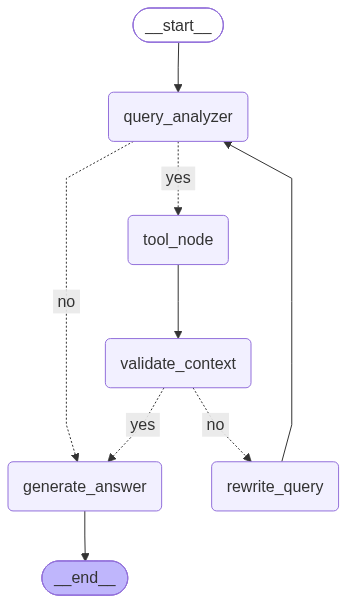

In [2]:
# Step 1: Bring your GraphBuilder into the notebook
# (Change 'my_workflow' to the real name of your Python file)
from src.grapg_builder.graph_builder import GraphBuilder
from src.config.config import Config

# Step 2: Set up your tools 
# (You need to plug in your real retriever and LLM here)
my_retriever =store.get_retriever() # Put your real retriever code here
my_llm = Config().get_llm()    
# res=my_llm.invoke("hiii")
# print(res,my_llm)# Put your real LLM code here

# Step 3: Create your graph builder
test_graph = GraphBuilder(retriever=my_retriever, llm=my_llm)
test=test_graph.build()
test
# Step 4: Make a name tag so the memory knows which notebook page to use
# my_config = {"configurable": {"thread_id": "test_chat_1"}}

# # Step 5: Ask a question and start the graph!
# my_question = "what is machine learning"
# final_answer = test_graph.run(question=my_question, config=my_config)

# # Step 6: Print the answer to see if it worked!
# print(f"this is final answer:\n\n{final_answer}")

In [3]:
my_config = {"configurable": {"thread_id": "test_chat_1"}}

# Step 5: Ask a question and start the graph!
my_question = "what is capital of france?"
final_answer = test_graph.run(question=my_question, config=my_config)

# Step 6: Print the answer to see if it worked!
print(f"this is final answer:\n\n{final_answer}")

Needs Tool Decision (yes/no): yes
Running Tool: tavily_search | Query: what is capital of france?
Running Tool: tavily_search | Query: what is capital of france?
calling tavily search tool.................
--- NODE: VALIDATE CONTEXT ---
Context Usable Decision (yes/no): yes
--- NODE: GENERATE ANSWER (LLM) ---
this is final answer:

{'messages': [HumanMessage(content='what is capital of france?', additional_kwargs={}, response_metadata={}, id='48bbcd20-cf14-484c-97e8-29000c2767a4'), AIMessage(content='The capital of France is Paris.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 1005, 'total_tokens': 1015, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'open

In [ ]:
from src.document_ingesition.document_processor import documentprocessor
from src.vector_store.vectorstore import Vectorstore
from pathlib import Path
from typing import List
from langchain_core.documents import Document
import re

processor = documentprocessor()

# Load documents
urls_file = Path(r"data\url.txt")
urls = None
    
if urls_file.exists():
    with open(urls_file, 'r') as f:
        urls = [line.strip() for line in f if line.strip()]
chunks = processor.process_urls(urls)


# process_chunks: List[Document]=[]

# clean_docs:List[Document]=[]
# for doc in docs:
#     text = doc.page_content

#     # 1. Normalize excessive whitespace and consecutive blank lines
#     text = re.sub(r'\r\n|\r', '\n', text)
#     text = re.sub(r'\n{2,}', '\n\n', text)
#     text = re.sub(r'[ \t]+', ' ', text)
#     text = re.sub(r"\n+", "", text)
#     # 2. Strip common blog/web noise artifacts (header bars, nav lines)
#     text = re.sub(r'(?:\|\s*)+(?:Posts|Archive|Search|Tags|FAQ)\b.*', '', text, flags=re.IGNORECASE)

#     clean_docs.append(Document(page_content=text,metadata=doc.metadata.copy()))



    

print("Documents loaded:", len(chunks))

# Split documents into chunks

print("Chunks created:", len(chunks))

# Create the vector store
store = Vectorstore()
store.create_vectorstore(chunks)

print("Vector store created successfully!")

my_retriever =store.get_retriever()

32 documents cleaned ..ready to split

Documents loaded: 251
Chunks created: 251
Vector store created successfully!


In [ ]:
def retriever_tool_fn(query: str) -> str:
            print("..............calling retriever tool............")
            docs: List[Document] = my_retriever.invoke(query)
            if not docs:
                return "No documents found."
            merged = []
            my_doc_bucket=docs
            print(f"\\n  this is my docs {len(my_doc_bucket)}\\n",flush=True)
            for i, d in enumerate(docs[:8], start=1):
                meta = d.metadata if hasattr(d, "metadata") else {}
                title = meta.get("title") or meta.get("source") or f"doc_{i}"
                merged.append(f"[{i}] title-{title} - content:= {d.page_content}")
            return "\n\n".join(merged)


ans =retriever_tool_fn("How does Chain of Thought help with task decomposition in agents")
print(ans)

..............calling retriever tool............
\n  this is my docs 2\n
[1] title-LLM Powered Autonomous Agents | Lil'Log - content:=access to proprietary information sources and more.Overview of a LLM-powered autonomous agent system.Component One: Planning#A complicated task usually involves many steps. An agent needs to know what they are and plan ahead.Task Decomposition#Chain of thought (CoT; Wei et al. 2022) has become a standard prompting technique for enhancing model performance on complex tasks. The model is instructed to “think step by step” to utilize more test-time computation to decompose hard tasks into smaller and simpler steps. CoT transforms big tasks into multiple manageable tasks and shed lights into an interpretation of the model’s thinking process.Tree of Thoughts (Yao et al. 2023) extends CoT by

[2] title-LLM Powered Autonomous Agents | Lil'Log - content:=thinking process.Tree of Thoughts (Yao et al. 2023) extends CoT by exploring multiple reasoning possibilities

In [11]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily_tool = TavilySearchResults(max_results=2)
def tavily_search_context(query: str) -> str:
            print("calling tavily search tool.................")
            results = tavily_tool.invoke({"query": query})
            if not results:
             return "No web search results found."
        
            # If Tavily already returns a string (e.g., an error message), return it directly
            if isinstance(results, str):
                return results
        
            # Combine all 3 dictionary results into one clean string
            context_parts = []
            for i, doc in enumerate(results, 1):
                
                content = doc.get("content", "")
                context_parts.append(f"Source {i} :\n{content[:600]}")
        
            return "\n\n-\n\n".join(context_parts)
result=tavily_search_context("what is porn?")
print(result)

calling tavily search tool.................
Source 1 :
Porn is anything you get off to. Porn is technically anything designed to arouse someone. Any content that's both explicitly sexual and erotic

-

Source 2 :
Please help us improve our site!

No thank you

Cornell University insignia  Cornell Law School Search Cornell

   
  

# pornography

Pornography, or “porn” for short, is material that depicts nudity or sexual acts for the purpose of sexual stimulation. However, the presence of nudity or sexual acts in piece of media does not necessarily make that media pornographic if the purpose of that media content is something other than sexual stimulation. Pornography can take the form of photographs, videos, written material, audio recordings, or animation, among other media formats.
